# Fake News Detection using TinyBERT + LoRA + Cross-Attention + Bi-GRU

**Project:** Lightweight GPU-accelerated fake news detection system

**Architecture:** TinyBERT-4L-312D encoder (with LoRA on query/value) -> cross-attention (headline attends to body) -> Bi-GRU -> max-pool -> linear + sigmoid

**Dataset:** WELFake (title, text, label; 1 = fake, 0 = real), 80/20 stratified split, random_state = 42

**Hardware used for training:** Google Colab, NVIDIA Tesla T4. Batch size 16 with max lengths 64 + 448 tokens keeps memory small.

**Training:** two stages, 5 epochs in total
- Stage 1 (epochs 1-2, lr 2e-4): TinyBERT backbone frozen, including its LoRA layers. Only cross-attention, Bi-GRU and classifier are trained.
- Stage 2 (epochs 3-5, lr 1e-5): whole backbone unfrozen (TinyBERT weights + LoRA) and fine-tuned with a low learning rate, together with the head.

**Output files:** `tinybert_fake_news_model/full_model.pth` (full state dict + config, used by `app.py`), LoRA adapter files and tokenizer files.

**To check the published model without retraining:** run sections 1-6, skip section 7 (training) and section 8 (save), then run section 9.

## 1. Install libraries and check GPU

In [ ]:
!pip install -q transformers==4.39.3 datasets==2.18.0 peft==0.10.0 accelerate==0.28.0 scikit-learn==1.6.0 kaggle

import torch
import sys

print('Python version:', sys.version)
print('PyTorch version:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())

if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('GPU Memory:', torch.cuda.get_device_properties(0).total_memory / 1024**3, 'GB')
else:
    print('⚠️ WARNING: GPU not detected!')
    print('Please enable GPU: Runtime → Change runtime type → Hardware accelerator → GPU')

## 2. Get the WELFake dataset
Upload `WELFake_Dataset.csv` (or its zip) to `/content/`. The dataset is available on Kaggle (WELFake fake news dataset).

In [ ]:
import os
import shutil
import zipfile

DESTINATION_DIR = '/content/data'
CSV_DEST_PATH = os.path.join(DESTINATION_DIR, 'WELFake_Dataset.csv')
os.makedirs(DESTINATION_DIR, exist_ok=True)

def find_source():
    # Look for the CSV or a zip containing it in /content
    for f in os.listdir('/content'):
        if f.endswith('.csv') and 'WELFake' in f:
            return os.path.join('/content', f)
    for f in os.listdir('/content'):
        if f.endswith('.zip') and 'WELFake' in f:
            return os.path.join('/content', f)
    return None

if not os.path.exists(CSV_DEST_PATH):
    source = find_source()
    if source is None:
        from google.colab import files
        print('Upload WELFake_Dataset.csv or its zip')
        uploaded = files.upload()
        source = os.path.join('/content', next(iter(uploaded)))

    if source.endswith('.zip'):
        with zipfile.ZipFile(source) as z:
            csv_name = next(n for n in z.namelist() if n.endswith('.csv'))
            with z.open(csv_name) as src_f, open(CSV_DEST_PATH, 'wb') as dst_f:
                shutil.copyfileobj(src_f, dst_f)
    else:
        shutil.move(source, CSV_DEST_PATH)

print('Dataset ready:', CSV_DEST_PATH, os.path.getsize(CSV_DEST_PATH) // 1024**2, 'MB')


## 3. Load and clean the dataset

In [ ]:
import pandas as pd

CSV_PATH = '/content/data/WELFake_Dataset.csv'

df = pd.read_csv(CSV_PATH, on_bad_lines='skip')  # skip malformed rows
print('Dataset shape:', df.shape)
print('\nColumns:', df.columns.tolist())
print('\nFirst few rows:')
print(df.head())

# Rename columns if needed (WELFake uses: serial_number, title, text, label)
if 'Title' in df.columns:
    df = df.rename(columns={'Title': 'title', 'Text': 'text', 'Label': 'label'})

# Clean data
df = df.dropna(subset=['title', 'text', 'label'])
df['label'] = df['label'].astype(int)

print('\n--- Dataset Statistics ---')
print(f'Total articles: {len(df):,}')
print('\nLabel distribution:')
print(df['label'].value_counts())
print('\nLabel percentages:')
print(df['label'].value_counts(normalize=True) * 100)

## 4. Train/test split (80/20, stratified)
The 20% test split is also used for the per-epoch validation scores in section 7. There is no separate validation set.

In [1]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df[['title', 'text', 'label']],
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

print('Train set size:', len(train_df))
print('Test set size:', len(test_df))
print('\nTrain label distribution:')
print(train_df['label'].value_counts())
print('\nTest label distribution:')
print(test_df['label'].value_counts())

Train set size: 57229
Test set size: 14308

Train label distribution:
label
1    29207
0    28022
Name: count, dtype: int64

Test label distribution:
label
1    7302
0    7006
Name: count, dtype: int64


## 5. Tokenisation, Dataset and DataLoaders
Headline: 64 tokens, body: 448 tokens (64 + 448 = 512). Bodies longer than 448 tokens are truncated.

In [ ]:
from transformers import AutoTokenizer
from torch.utils.data import Dataset, DataLoader
import torch

MODEL_NAME = 'huawei-noah/TinyBERT_General_4L_312D'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

MAX_HEADLINE_LEN = 64
MAX_BODY_LEN = 448
BATCH_SIZE = 16  # small batch keeps GPU memory low

class FakeNewsDataset(Dataset):
    def __init__(self, df):
        self.titles = df['title'].astype(str).tolist()
        self.texts = df['text'].astype(str).tolist()
        self.labels = df['label'].astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        title = self.titles[idx]
        body = self.texts[idx]
        label = self.labels[idx]

        t = tokenizer(
            title,
            max_length=MAX_HEADLINE_LEN,
            truncation=True,
            padding='max_length',
            return_tensors='pt'
        )
        b = tokenizer(
            body,
            max_length=MAX_BODY_LEN,
            truncation=True,
            padding='max_length',
            return_tensors='pt'
        )

        return {
            'headline_ids': t['input_ids'].squeeze(0),
            'headline_mask': t['attention_mask'].squeeze(0),
            'body_ids': b['input_ids'].squeeze(0),
            'body_mask': b['attention_mask'].squeeze(0),
            'label': torch.tensor(label, dtype=torch.float)
        }

train_dataset = FakeNewsDataset(train_df)
test_dataset = FakeNewsDataset(test_df)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f'Train batches: {len(train_loader)}')
print(f'Test batches: {len(test_loader)}')
print(f'\nSample batch shape:')
sample = next(iter(train_loader))
for key, val in sample.items():
    print(f'  {key}: {val.shape}')

## 6. Model: TinyBERT + LoRA + cross-attention + Bi-GRU
Note: `dropout=0.1` inside `nn.GRU` has no effect with `num_layers=1` (PyTorch prints a warning). It is kept as is, so the code matches the trained checkpoint.

In [ ]:
import torch.nn as nn
from transformers import AutoModel
from peft import LoraConfig, get_peft_model

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class TinyBertCrossAttnBiGRU(nn.Module):
    def __init__(self, model_name=MODEL_NAME, lora_r=4, lora_alpha=32,
                 num_heads=8, gru_hidden=64):
        super().__init__()

        # TinyBERT backbone
        self.backbone = AutoModel.from_pretrained(model_name)
        hidden_size = self.backbone.config.hidden_size  # 312

        # LoRA configuration
        lora_cfg = LoraConfig(
            r=lora_r,
            lora_alpha=lora_alpha,
            target_modules=['query', 'value'],
            lora_dropout=0.1,
            bias='none',
            task_type='FEATURE_EXTRACTION'  # backbone used as an encoder, head is custom
        )
        self.backbone = get_peft_model(self.backbone, lora_cfg)

        # Cross-attention (headline as query, body as key/value)
        self.cross_attn = nn.MultiheadAttention(
            embed_dim=hidden_size,
            num_heads=num_heads,
            dropout=0.1,
            batch_first=True
        )

        # Bidirectional GRU
        self.gru = nn.GRU(
            input_size=hidden_size,
            hidden_size=gru_hidden,
            num_layers=1,
            bidirectional=True,
            batch_first=True,
            dropout=0.1  # no effect with num_layers=1
        )

        self.dropout = nn.Dropout(0.2)
        self.fc = nn.Linear(2 * gru_hidden, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, headline_ids, headline_mask, body_ids, body_mask):
        # Encode headline and body separately
        h = self.backbone(
            input_ids=headline_ids,
            attention_mask=headline_mask
        ).last_hidden_state

        b = self.backbone(
            input_ids=body_ids,
            attention_mask=body_mask
        ).last_hidden_state

        # Cross-attention: headline attends to body
        cross, _ = self.cross_attn(
            query=h,
            key=b,
            value=b,
            key_padding_mask=(body_mask == 0)
        )

        # Concatenate headline + cross-attended features
        combined = torch.cat([h, cross], dim=1)

        # Bi-GRU
        gru_out, _ = self.gru(combined)

        # Global max pooling
        pooled, _ = torch.max(gru_out, dim=1)

        # Classification
        x = self.dropout(pooled)
        logit = self.fc(x)
        prob = self.sigmoid(logit).squeeze(-1)
        return prob

# Initialize model
model = TinyBertCrossAttnBiGRU().to(device)

# Print model info
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total parameters: {total_params/1e6:.2f}M')
print(f'Trainable parameters: {trainable_params/1e6:.2f}M')
print(f'Model size: ~{total_params*4/1024**2:.1f}MB (FP32)')

## 7. Training (two stages, 5 epochs)
Skip this section if you only want to evaluate the published model (section 9).

In [ ]:
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm.auto import tqdm

EPOCHS = 5
LR_STAGE1 = 2e-4
LR_STAGE2 = 1e-5
criterion = nn.BCELoss()

def set_stage(stage):
    """Configure training stage (frozen vs unfrozen backbone)"""
    if stage == 1:
        # Stage 1: freeze the whole backbone (TinyBERT and its LoRA layers);
        # train only cross-attention + Bi-GRU + classifier
        for p in model.backbone.parameters():
            p.requires_grad = False
        for module in [model.cross_attn, model.gru, model.fc]:
            for p in module.parameters():
                p.requires_grad = True
        lr = LR_STAGE1
        print('Stage 1: backbone frozen (incl. LoRA), training cross-attention + GRU + classifier')
    else:
        # Stage 2: unfreeze the whole backbone (TinyBERT weights + LoRA)
        # and fine-tune everything with a low learning rate
        for p in model.backbone.parameters():
            p.requires_grad = True
        lr = LR_STAGE2
        print('Stage 2: full backbone unfrozen, fine-tuning all layers at low LR')

    opt = AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                lr=lr, weight_decay=0.01)
    return opt

optimizer = set_stage(stage=1)

def train_one_epoch(epoch, stage):
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []

    pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS} (Stage {stage})')
    for batch in pbar:
        h_ids = batch['headline_ids'].to(device)
        h_mask = batch['headline_mask'].to(device)
        b_ids = batch['body_ids'].to(device)
        b_mask = batch['body_mask'].to(device)
        labels = batch['label'].to(device)

        optimizer.zero_grad()
        probs = model(h_ids, h_mask, b_ids, b_mask)
        loss = criterion(probs, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        preds = (probs.detach() >= 0.5).long().cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.cpu().numpy())
        pbar.set_postfix(loss=loss.item())

    avg_loss = total_loss / len(train_dataset)
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    return avg_loss, acc, f1

def evaluate():
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in tqdm(test_loader, desc='Evaluating'):
            h_ids = batch['headline_ids'].to(device)
            h_mask = batch['headline_mask'].to(device)
            b_ids = batch['body_ids'].to(device)
            b_mask = batch['body_mask'].to(device)
            labels = batch['label'].to(device)

            probs = model(h_ids, h_mask, b_ids, b_mask)
            preds = (probs >= 0.5).long().cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    return acc, f1, all_labels, all_preds

# Training loop
print('\n' + '='*60)
print('STARTING TRAINING')
print('='*60 + '\n')

for epoch in range(EPOCHS):
    # Switch to stage 2 after 2 epochs
    if epoch == 2:
        optimizer = set_stage(stage=2)

    stage = 1 if epoch < 2 else 2
    tr_loss, tr_acc, tr_f1 = train_one_epoch(epoch, stage)
    val_acc, val_f1, _, _ = evaluate()

    print(f'\nEpoch {epoch+1}/{EPOCHS} Results:')
    print(f'   Train -> Loss: {tr_loss:.4f}, Acc: {tr_acc:.4f}, F1: {tr_f1:.4f}')
    print(f'   Test  -> Acc: {val_acc:.4f}, F1: {val_f1:.4f}\n')

print('\n' + '='*60)
print('TRAINING COMPLETE!')
print('='*60)

## 8. Final evaluation and save the model

In [ ]:
import os
from sklearn.metrics import confusion_matrix, classification_report

# Final evaluation
print('\n' + '='*60)
print('FINAL EVALUATION ON TEST SET')
print('='*60 + '\n')

val_acc, val_f1, true_labels, pred_labels = evaluate()

print(f'Test Accuracy: {val_acc:.4f}')
print(f'Test F1-Score: {val_f1:.4f}\n')

print('Confusion Matrix:')
cm = confusion_matrix(true_labels, pred_labels)
print(cm)
print(f'\nTrue Negatives:  {cm[0,0]}')
print(f'False Positives: {cm[0,1]}')
print(f'False Negatives: {cm[1,0]}')
print(f'True Positives:  {cm[1,1]}')

print('\nClassification Report:')
print(classification_report(true_labels, pred_labels, target_names=['Real', 'Fake']))

# Save model
SAVE_DIR = '/content/tinybert_fake_news_model'
os.makedirs(SAVE_DIR, exist_ok=True)
model.backbone.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
torch.save({
    'model_state_dict': model.state_dict(),
    'config': {
        'model_name': MODEL_NAME,
        'max_headline_len': MAX_HEADLINE_LEN,
        'max_body_len': MAX_BODY_LEN,
        'batch_size': BATCH_SIZE,
        'epochs': EPOCHS
    }
}, f'{SAVE_DIR}/full_model.pth')

print(f'\nModel saved to: {SAVE_DIR}')

# Test prediction function
def predict_one(headline, body):
    model.eval()
    with torch.no_grad():
        t = tokenizer(headline, max_length=MAX_HEADLINE_LEN, truncation=True,
                      padding='max_length', return_tensors='pt')
        b = tokenizer(body, max_length=MAX_BODY_LEN, truncation=True,
                      padding='max_length', return_tensors='pt')
        probs = model(
            t['input_ids'].to(device),
            t['attention_mask'].to(device),
            b['input_ids'].to(device),
            b['attention_mask'].to(device)
        )
        p = probs.item()
        label = 'FAKE' if p >= 0.5 else 'REAL'
        return label, p

# Test example
print('\n' + '='*60)
print('TESTING PREDICTION')
print('='*60 + '\n')

headline = 'BREAKING: Celebrity dies in shocking accident'
body = 'The celebrity announced a new tour yesterday and thanked fans for their support.'

label, prob = predict_one(headline, body)
print(f'Headline: "{headline}"')
print(f'Body: "{body}"')
print(f'\nPrediction: {label}')
print(f'Confidence: {prob:.4f}')
print(f'Fake probability: {prob:.2%}')
print(f'Real probability: {(1-prob):.2%}')

## 9. Evaluate the published model (no retraining)
Downloads `full_model.pth` from this repository, loads it into the same architecture and scores it on the same test split. Run sections 1-6 first.

*Saved outputs below come from scoring the published `full_model.pth` on all 14,308 test articles (CPU run on 11 Nov 2026, WELFake copy from Hugging Face `davanstrien/WELFake`, same 80/20 split with random_state = 42, which gives the same 7,006 real / 7,302 fake test counts).*

In [2]:
!wget -q -O /content/full_model.pth https://github.com/Grandhiteja/Fake-News-Predictions-/raw/master/tinybert_fake_news_model/full_model.pth

import torch
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

ckpt = torch.load('/content/full_model.pth', map_location=device, weights_only=False)
print('Checkpoint config:', ckpt['config'])
model = TinyBertCrossAttnBiGRU().to(device)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for batch in tqdm(test_loader, desc='Evaluating saved model'):
        probs = model(batch['headline_ids'].to(device), batch['headline_mask'].to(device),
                      batch['body_ids'].to(device), batch['body_mask'].to(device))
        y_pred.extend((probs >= 0.5).long().cpu().numpy())
        y_true.extend(batch['label'].long().numpy())

print(f'Test samples: {len(y_true)}')
print(f'Accuracy: {accuracy_score(y_true, y_pred):.4f}')
print(f'F1 (Fake): {f1_score(y_true, y_pred):.4f}')
cm = confusion_matrix(y_true, y_pred)
print(cm)
print(classification_report(y_true, y_pred, target_names=['Real', 'Fake'], digits=4))


Checkpoint config: {'model_name': 'huawei-noah/TinyBERT_General_4L_312D', 'max_headline_len': 64, 'max_body_len': 448, 'batch_size': 16, 'epochs': 5}
Test samples: 14308
Accuracy: 0.9936
F1 (Fake): 0.9938
[[6962   44]
 [  47 7255]]
              precision    recall  f1-score   support

        Real     0.9933    0.9937    0.9935      7006
        Fake     0.9940    0.9936    0.9938      7302

    accuracy                         0.9936     14308
   macro avg     0.9936    0.9936    0.9936     14308
weighted avg     0.9936    0.9936    0.9936     14308


## 10. Confusion matrix heatmap

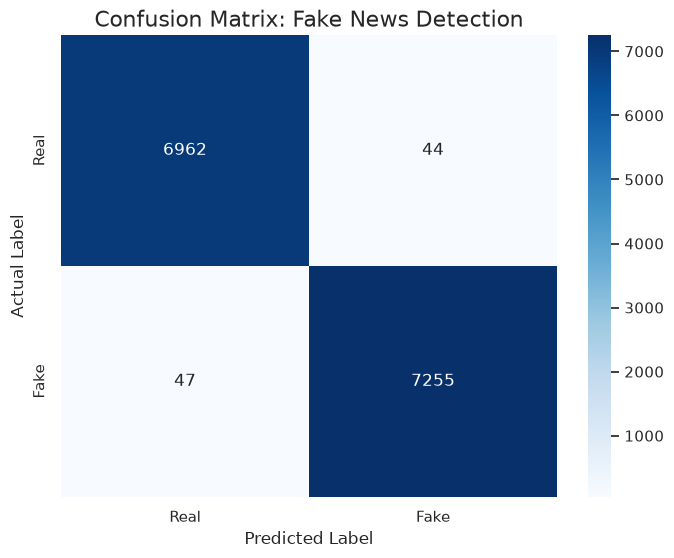

In [3]:
plt.figure(figsize=(8, 6))
sns.set(style='whitegrid')
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
plt.title('Confusion Matrix: Fake News Detection', fontsize=16)
plt.ylabel('Actual Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.show()


## Known limitations
- The test split doubles as the validation set during training, so there is no separate held-out validation set.
- Headline padding tokens are not masked before the Bi-GRU and max-pool.
- Only the first 448 body tokens are used.
- The 0.5 threshold is fixed and the probabilities are not calibrated.
- WELFake merges several public datasets. High scores may partly reflect source-specific style, so performance on news from other sources should be tested.